# HeatAhead Workstream 2: analysis, second thread (executed on the IBM z17 LinuxONE guest)

Team NYU Tingineers, IBM Z Datathon 2026. This notebook runs the six pipeline scripts in `~/heatahead/stream2/` on the s390x guest and shows the tables and figures that feed `02_stream2_report.md`.

| step | script | deliverable |
|---|---|---|
| 0 | `s2_00_stage_protect.py` | stage raw tables, HMAC-SHA256 apartment pseudonymization, DFLTCC deflate and CPACF AES-256-GCM timings on the real files |
| 1 | `s2_01_clean.py` | team traps and Person 3 join rules: int64 keys, building_id joins, heat-only filter, holiday gaps, 2010+ violations |
| 2 | `s2_02_violation_tier.py` | Deliverable 1: 48 h cluster tiers vs verified heat violations, inspector saturation by day |
| 4 | `s2_04_forecast_only.py` | Deliverable 3: Forecast-Only building group, 2025-26 holdout, Feb 7-9 2026, archived forecast cross-check |
| 3 | `s2_03_geography.py` | Deliverable 2: Community District and Council District tables, Bronx CD 7/4/5 pitch numbers |
| 5 | `s2_05_boiler_join.py` | Deliverable 4: DOB boiler defects (52dp-yji6) and DEP fuel (f4rp-2kvy) joined on bin |

Step 3 runs after step 4 because the district tables count Chronic and Forecast-Only buildings.

In [1]:
import platform, subprocess
print(platform.machine(), "|", subprocess.run("grep -m1 machine /proc/cpuinfo", shell=True, capture_output=True, text=True).stdout.strip())
feats = subprocess.run("grep -o -w -E 'dflt|nnpa|vx' /proc/cpuinfo | sort -u", shell=True, capture_output=True, text=True).stdout
print("facilities:", " ".join(feats.split()))
import pandas as pd, numpy as np
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

s390x | processor 0: version = FF,  identification = 09DFD8,  machine = 9175
facilities: dflt nnpa vx


## Step 0: stage and protect on the z17 (DFLTCC deflate, CPACF AES-256-GCM, HMAC-SHA256)

In [2]:
%run s2_00_stage_protect.py

STEP 0: stage + hardware data protection on s390x
  processor 0: version = FF,  identification = 09DFD8,  machine = 9175 | dflt True | nnpa True
[14:50:11] inflate shipped gzip streams ...
  ygpa-z7cr.csv already inflated (344.8 MB)
  wvxf-dwi5.csv already inflated (26.7 MB)
[14:50:11] inflate shipped gzip streams done in 0.0 s
  pseudonymized extracts already exist; reusing (pass --force to redo)
[14:50:11] benchmark pass: hardware on (DFLTCC default, CPACF on) ...
[14:50:19] benchmark pass: hardware on (DFLTCC default, CPACF on) done in 8.4 s
[14:50:19] benchmark pass: DFLTCC=0 (deflate in software) ...
[14:50:54] benchmark pass: DFLTCC=0 (deflate in software) done in 34.7 s
[14:50:54] benchmark pass: CPACF masked (AES + SHA instructions off, OPENSSL_s390xcap) ...
[14:51:16] benchmark pass: CPACF masked (AES + SHA instructions off, OPENSSL_s390xcap) done in 21.5 s
# IBM z17 hardware execution log (Workstream 2, measured on the real project files)

- Machine: `processor 0: version = F

## Step 1: clean, cast keys, build the working tables

In [3]:
%run s2_01_clean.py

[14:52:04] load pseudonymized complaints ...
[14:52:08] load pseudonymized complaints done in 4.9 s
[14:52:17] write heat_rows.csv ...
[14:52:29] write heat_rows.csv done in 12.1 s
[14:52:29] collapse to distinct complaints ...
[14:52:31] collapse to distinct complaints done in 1.7 s
  heat rows 1,852,994 -> distinct complaints 1,843,856 at 107,825 buildings; 45.1% of rows flagged duplicate, 49.7% anonymous
[14:52:42] violations ...
[14:52:44] violations done in 2.1 s
  violations kept 199,823 (dropped 23,607 pre-2010); heat 68,739, hot water 131,084; last inspection 2026-10-14
[14:52:44] PLUTO ...
[14:52:57] PLUTO done in 12.7 s
  PLUTO lots 858,284; 3+ unit lots 172,485 (172,485 overlap the team's pluto_res3plus file of 172,485)
[14:52:57] HPD buildings + registrations ...
[14:52:59] HPD buildings + registrations done in 2.4 s
[14:52:59] building universe ...
[14:53:02] building universe done in 3.3 s
  universe 116,139 buildings; 111,657 matched to PLUTO on bbl, 71,149 in the 3+ uni

## Step 2: Deliverable 1, violation tier and label credibility

In [4]:
%run s2_02_violation_tier.py

[14:53:03] load working tables ...
[14:53:06] load working tables done in 3.0 s
[14:53:06] sessionize complaints into 48 h clusters ...
[14:53:12] sessionize complaints into 48 h clusters done in 6.1 s
  1,031,133 clusters; 334,361 have 2+ distinct complaints within 48 h (32.4% of clusters, 62.2% of complaints)
[14:53:12] match clusters to heat violations (0-7 d, 0-14 d) ...
[14:53:32] match clusters to heat violations (0-7 d, 0-14 d) done in 19.6 s
[14:53:32] confirmation rates ...
                           level  n_clusters  rate_7d  rate_14d  median_lag_days_confirmed
                     1 complaint      693823 0.047805  0.062200                        3.0
   2+ complaints (primary label)      333736 0.089280  0.114926                        3.0
2+ complaints from 2+ apartments      198705 0.105387  0.133439                        3.0
     2+ non-duplicate complaints       61568 0.108433  0.133381                        3.0
                   3+ complaints      151674 0.106109  0.

,level,n_clusters,rate_7d,rate_14d,median_lag_days_confirmed
0,1 complaint,693823,0.047805,0.062200,3.0
1,2+ complaints (primary label),333736,0.089280,0.114926,3.0
2,2+ complaints from 2+ apartments,198705,0.105387,0.133439,3.0
3,2+ non-duplicate complaints,61568,0.108433,0.133381,3.0
4,3+ complaints,151674,0.106109,0.135277,3.0
5,5+ complaints,51865,0.123089,0.154189,3.0
6,exactly 2,182062,0.075260,0.097972,3.0
7,exactly 3-4,99809,0.097286,0.125450,3.0


,level,n_clusters,rate_7d,rate_14d
100,Frigid,13624,0.145552,0.187904
101,Freezing,16594,0.132518,0.169278
102,Cold,17774,0.114381,0.148194
103,Mild,7881,0.035528,0.060018


,dimension,level,days,complaints,clusters_2plus,confirmed,mean_tmin,dup_share,rate_7d_2plus
0,"daily complaint volume bin, Frigid+Freezing da...",501-1000,98,81395,14382,1112,28.102041,0.436864,0.077319
1,"daily complaint volume bin, Frigid+Freezing da...",1001-2000,254,351742,62979,6782,25.925197,0.458340,0.107687
2,"daily complaint volume bin, Frigid+Freezing da...",2001-3000,83,198737,37407,4192,21.963855,0.477088,0.112065
3,"daily complaint volume bin, Frigid+Freezing da...",3001-4500,35,129434,23778,2749,14.314286,0.535465,0.115611
4,"daily complaint volume bin, Frigid+Freezing da...",4500+,12,60785,11124,1153,8.166667,0.538326,0.103650


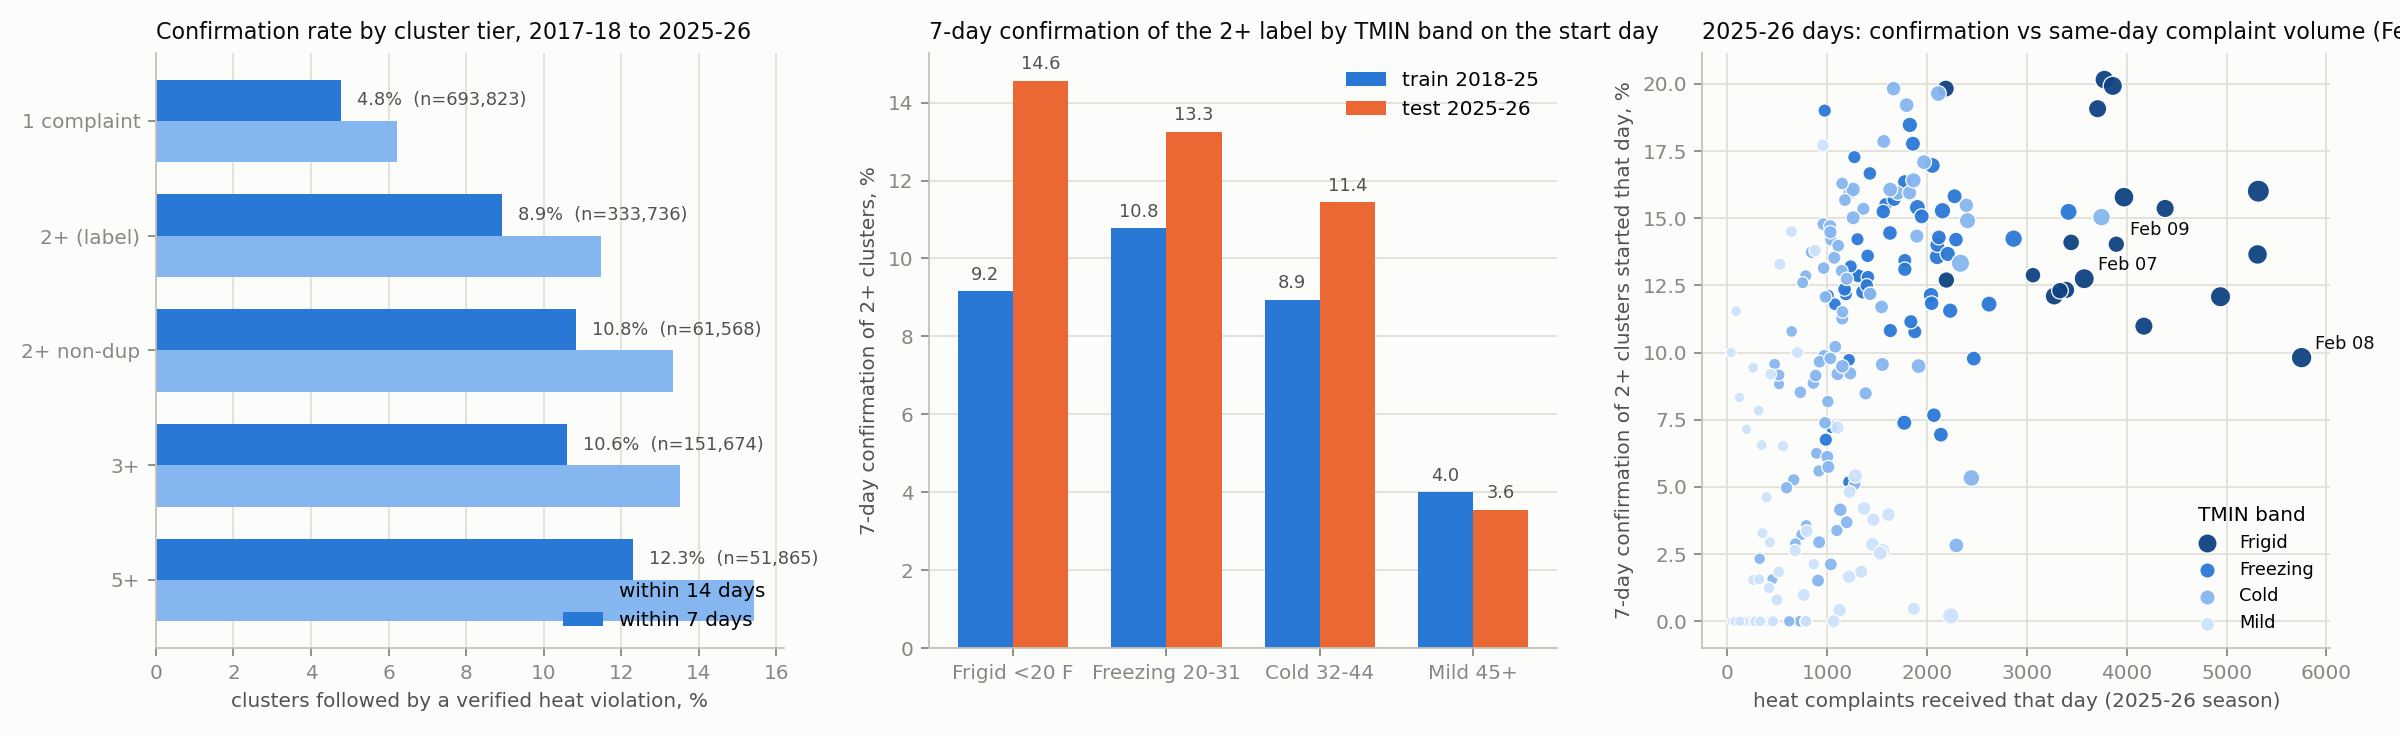

In [5]:
from IPython.display import Image, display
s = pd.read_csv(OUT / "violation_confirmation_summary.csv")
display(s[(s.window == "all seasons") & (s.dimension == "cluster tier")][["level", "n_clusters", "rate_7d", "rate_14d", "median_lag_days_confirmed"]])
display(s[(s.window == "test 2025-26") & (s.dimension.str.startswith("TMIN band on cluster start day (2+"))][["level", "n_clusters", "rate_7d", "rate_14d"]])
display(pd.read_csv(OUT / "violation_saturation_by_volume.csv"))
display(Image(filename=str(OUT / "fig_violation_confirmation.png")))

## Step 4: Deliverable 3, the Forecast-Only building group

In [6]:
%run s2_04_forecast_only.py

[14:53:43] load ...
[14:53:51] load done in 7.2 s
[14:53:51] training-window band features ...
[14:53:52] training-window band features done in 1.3 s
[14:53:52] groups ...
[14:53:52] groups done in 0.2 s
  chronic 38,549 buildings | forecast-only strict 18,814 (491,865 units) | broad 33,805 (1,022,385 units)
[14:53:52] 2025-26 holdout outcomes ...
[14:53:53] 2025-26 holdout outcomes done in 0.4 s
                    group  buildings     units  share_failed48_2025_26  share_failed48_feb7_9  fail48_events_feb7_9
                  chronic      38549 2976945.0                0.271576               0.046538                1862.0
     forecast_only_strict      18814  491865.0                0.033645               0.003774                  73.0
forecast_only_broad_extra      14991  530520.0                0.119872               0.015276                 238.0
                cold_only      17481  301303.0                0.025113               0.002403                  43.0
   no_training_compl

,group,buildings,units,share_complained_2025_26,share_failed48_2025_26,share_verified_2025_26,share_heat_violation_2025_26,share_failed48_feb7_9,share_any_complaint_feb7_9,fail48_events_2025_26,fail48_events_feb7_9,units_in_buildings_failed_feb7_9,test_cdays_per_1000_bldg_per_day_frigid,test_cdays_per_1000_bldg_per_day_freezing,test_cdays_per_1000_bldg_per_day_cold,test_cdays_per_1000_bldg_per_day_mild
0,chronic,38549,2976945.0,0.485071,0.271576,0.057070,0.096111,0.046538,0.109679,47392.0,1862.0,196451.0,46.120385,23.006683,16.790643,7.196093
1,forecast_only_strict,18814,491865.0,0.135112,0.033645,0.005049,0.014723,0.003774,0.015733,1096.0,73.0,2123.0,5.083001,1.892003,1.152732,0.454102
2,forecast_only_broad_extra,14991,530520.0,0.323728,0.119872,0.023014,0.055367,0.015276,0.051297,4022.0,238.0,24406.0,17.775578,7.530159,4.496031,1.494375
3,cold_only,17481,301303.0,0.107259,0.025113,0.003776,0.012242,0.002403,0.010240,765.0,43.0,1976.0,3.200467,1.393821,1.051141,0.410383
4,no_training_complaints,26304,504365.0,0.387774,0.060713,0.009048,0.031326,0.005512,0.034595,2598.0,150.0,4101.0,9.552279,4.083907,2.654539,1.067783


,group,subfreezing_tier,buildings,units,share_failed48_2025_26,share_verified_2025_26,share_failed48_feb7_9,failed48_feb7_9,share_complained_2025_26,mean_c_last1,share_c_last1_zero
0,forecast_only_broad,1,20775,491497.0,0.033309,0.005439,0.003514,73,0.132563,0.308448,0.752635
1,forecast_only_broad,2-3,8511,307365.0,0.078487,0.011397,0.008342,71,0.270591,0.804253,0.629891
2,forecast_only_broad,4-9,3705,173250.0,0.192173,0.039676,0.025641,95,0.470985,2.162213,0.455870
3,forecast_only_broad,10+,814,50273.0,0.439803,0.101966,0.074939,61,0.728501,7.074939,0.223587
4,forecast_only_strict,1,14671,339937.0,0.024061,0.003885,0.002522,37,0.103538,0.252539,0.758435
5,forecast_only_strict,2-3,3524,128498.0,0.055902,0.005959,0.007662,27,0.223893,0.666005,0.636776
6,forecast_only_strict,4-9,595,21942.0,0.124370,0.023529,0.011765,7,0.364706,1.726050,0.537815
7,forecast_only_strict,10+,24,1488.0,0.375000,0.125000,0.000000,0,0.708333,6.458333,0.333333
8,chronic,0,11236,487686.0,0.044678,0.006141,0.004183,47,0.161000,0.360449,0.802065
9,chronic,1,4906,334181.0,0.106400,0.014064,0.008357,41,0.297799,0.822870,0.653078


ranking,cold-sensitivity x units (tenants at risk),cold-sensitivity: sub-freezing reaction rate (2018-25),last season heat violations (2024-25),last season total complaints (2024-25),trailing 14-day complaints before Feb 7,training-window total complaints (2018-25)
k,,,,,,
100,0.160,0.590,0.300,0.560,0.720,0.550
500,0.242,0.408,0.236,0.406,0.572,0.354
1000,0.254,0.337,0.215,0.346,0.477,0.309
2500,0.220,0.258,0.172,0.258,0.346,0.244


,0,1,2,3,4,5
building_id,46149,749553,116710,812435,804145,64588
bbl,2030680033.0,5000450001.0,2032490107.0,5014940050.0,1019930088.0,2024220026.0
bin,2094641.0,5001022.0,2015337.0,5109282.0,1082765.0,2001964.0
borough,Bronx,Staten Island,Bronx,Staten Island,Manhattan,Bronx
cd,206.0,501.0,208.0,501.0,109.0,204.0
council,15.0,49.0,14.0,49.0,7.0,16.0
yearbuilt,1931.0,1984.0,1930.0,1969.0,1905.0,1918.0
unitsres,45.0,16.0,3.0,164.0,45.0,34.0
numfloors,7.0,2.0,3.0,2.0,6.0,6.0
bldgclass,D7,C9,C0,C1,C7,C1


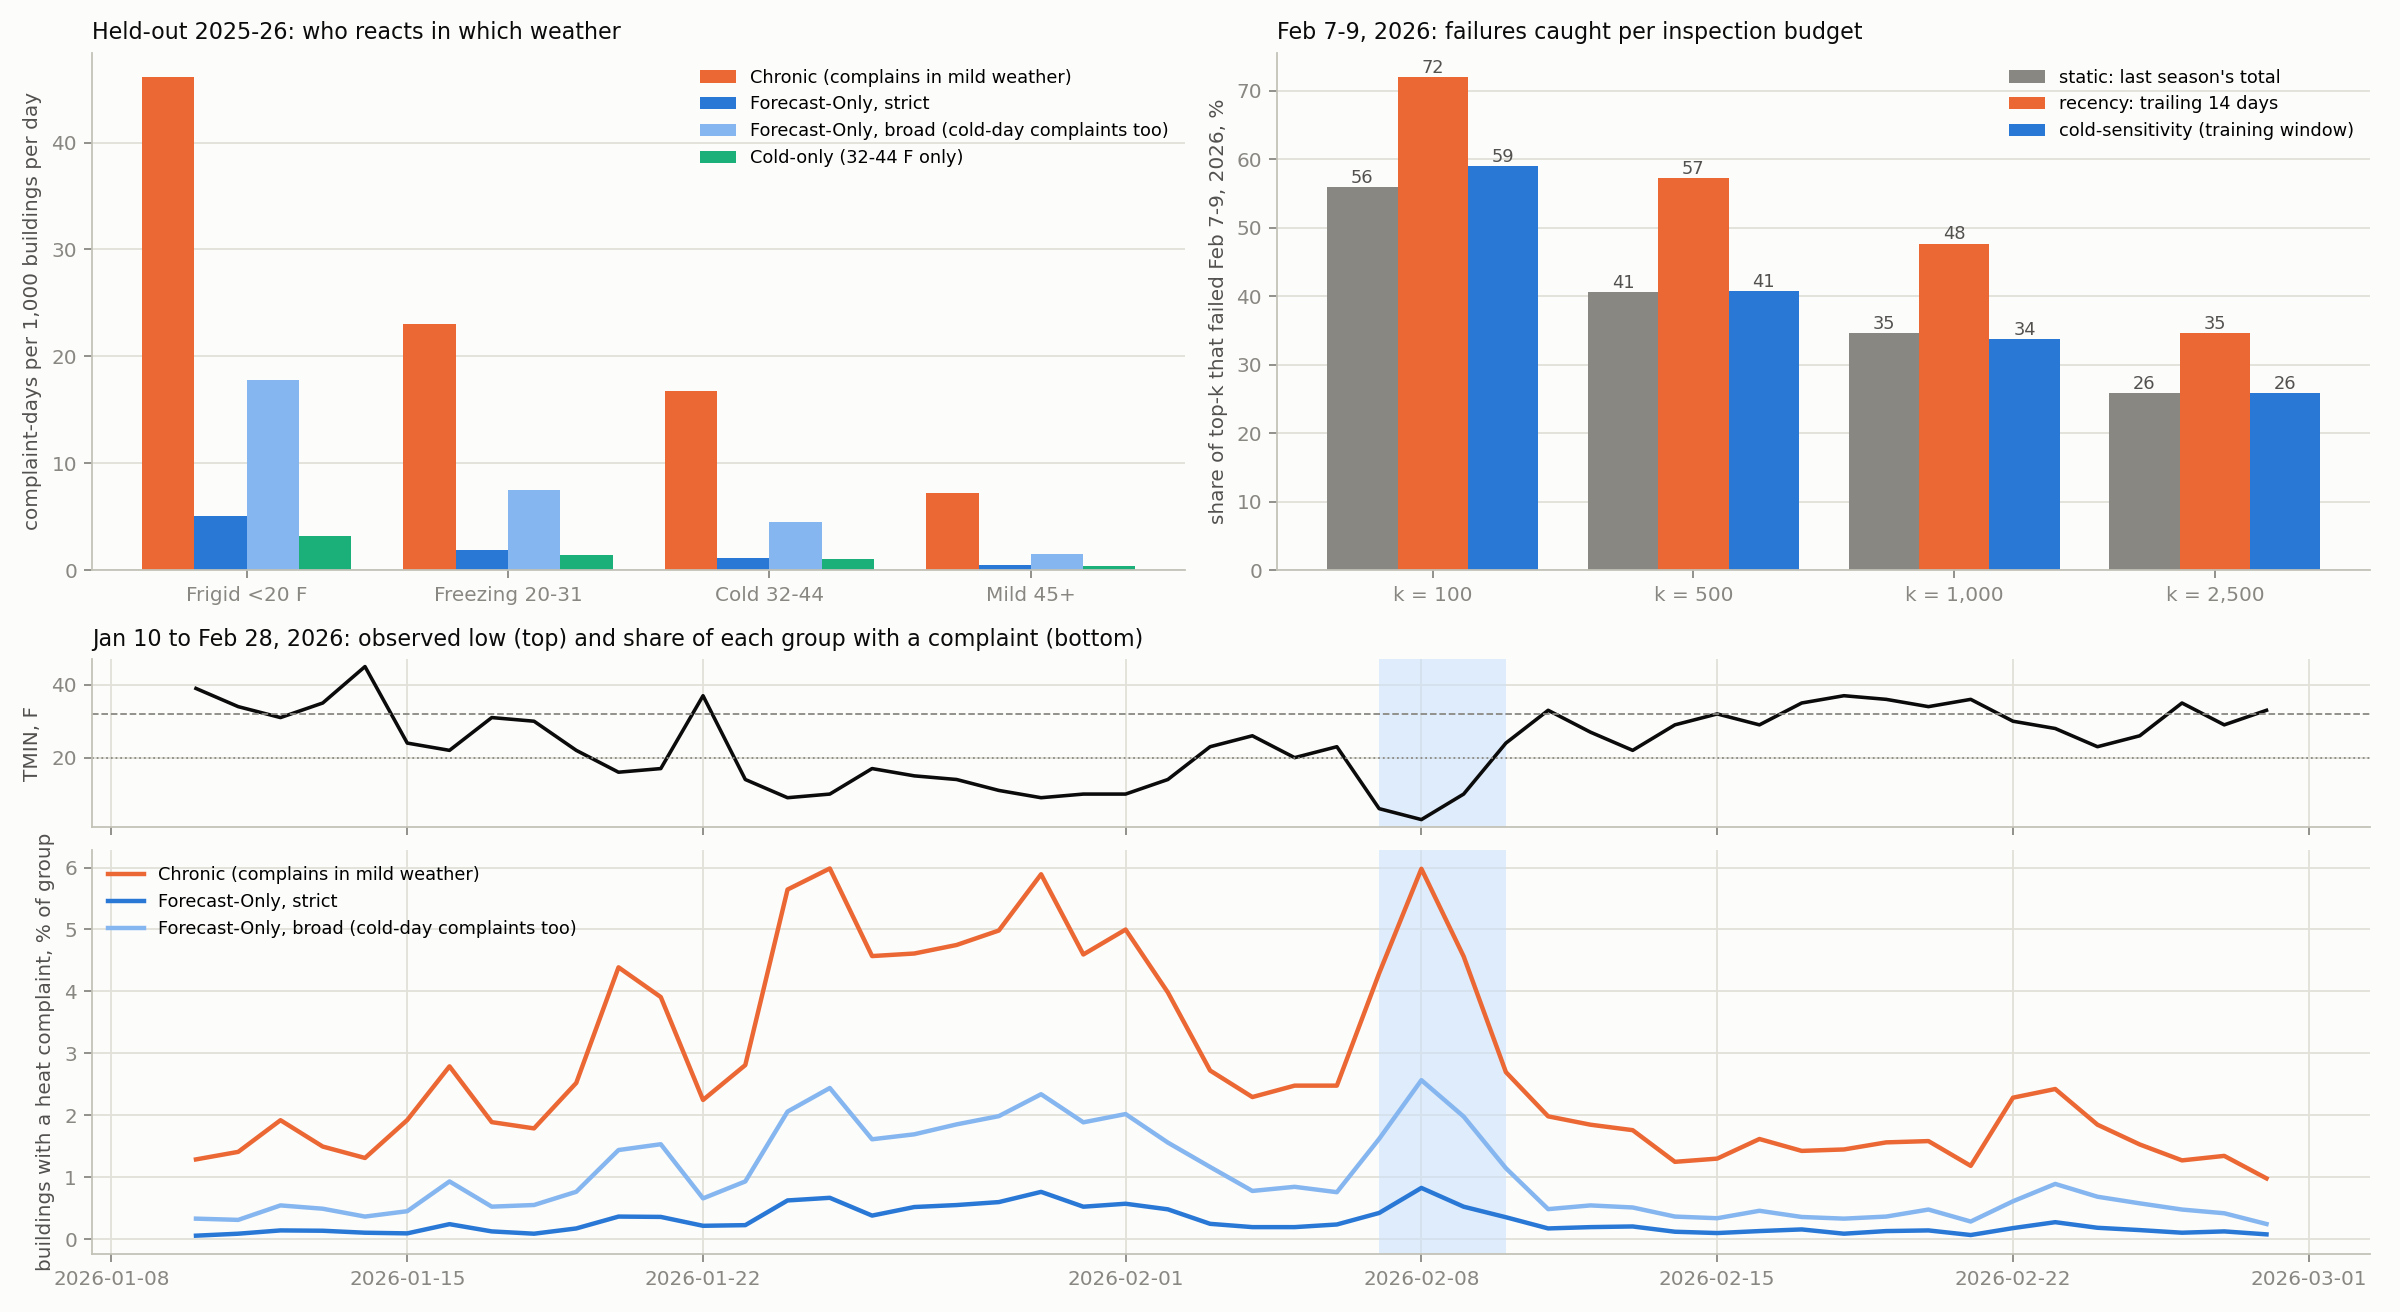

In [7]:
display(pd.read_csv(OUT / "forecast_only_group_summary.csv"))
display(pd.read_csv(OUT / "forecast_only_intensity_tiers.csv"))
pk = pd.read_csv(OUT / "forecast_only_precision_at_k.csv")
display(pk.pivot(index="k", columns="ranking", values="precision").round(3))
display(pd.read_csv(OUT / "forecast_only_examples.csv").head(6).T)
display(Image(filename=str(OUT / "fig_forecast_only_regimes.png")))

## Step 3: Deliverable 2, geography and the Bronx Community Districts 7, 4 and 5

In [8]:
%run s2_03_geography.py

[14:53:57] load ...
[14:54:06] load done in 8.7 s
[14:54:06] per-building totals ...
[14:54:07] per-building totals done in 0.4 s
[14:54:07] community districts ...
[14:54:07] community districts done in 0.3 s
                                  district  residential_units  heat_complaints_2025_26  complaints_per_100_units_2025_26  feb7_9_2026_complaints  forecast_only_strict_buildings
                                Bronx CD 7            56577.0                    16675                         29.473107                     624                             184
                                Bronx CD 4            58204.0                    15150                         26.029139                     686                             189
                                Bronx CD 5            57144.0                    12282                         21.493070                     519                             171
                           Manhattan CD 12            75854.0                    1

,0,1,2,3,4,5,6,7,8
district,Bronx CD 7,Bronx CD 4,Bronx CD 5,Manhattan CD 12,Brooklyn CD 14,Bronx CD 7 + 4 + 5 together,all five focus districts,rest of New York City (54 other districts),New York City total
residential_buildings_all,2889,2474,2604,2076,10769,7967,20812,746538,767350
residential_buildings_3plus,1667,1791,1516,1882,2080,4974,8936,163535,172471
residential_units,56577.0,58204.0,57144.0,75854.0,65404.0,171925.0,313183.0,3422191.0,3735374.0
estimated_tenants,144271.35,148420.2,145717.2,193427.7,166780.2,438408.75,798616.65,8726587.05,9525203.7
heat_complaints_all_seasons,102538,93434,89955,112447,65994,285927,464368,1364151,1828519
heat_complaints_2025_26,16675,15150,12282,18968,11473,44107,74548,226928,301476
complaints_per_100_units_2025_26,29.473107,26.029139,21.49307,25.005932,17.541741,25.654791,23.803335,6.631073,8.070838
complaints_per_residential_building_2025_26,5.771893,6.123686,4.71659,9.136802,1.065373,5.536212,3.581972,0.303974,0.392879
failure_events_48h_2025_26,3179,2943,2444,3552,2165,8566,14283,41336,55619


,cd_label,residential_units,heat_complaints_2025_26,complaints_per_100_units_2025_26,feb7_9_2026_complaints,chronic_buildings,forecast_only_strict_buildings,latitude_centroid,longitude_centroid
19,Bronx CD 7,56577.0,16675,29.473107,624,1033,184,40.869949,-73.889754
16,Bronx CD 4,58204.0,15150,26.029139,686,924,189,40.834774,-73.918408
11,Manhattan CD 12,75854.0,18968,25.005932,695,1300,148,40.850447,-73.933169
9,Manhattan CD 10,61895.0,14064,22.722352,527,1034,269,40.810958,-73.946591
17,Bronx CD 5,57144.0,12282,21.493070,519,880,171,40.852694,-73.908488
18,Bronx CD 6,36810.0,7835,21.284977,352,771,204,40.849531,-73.888513
8,Manhattan CD 9,46830.0,9065,19.357250,372,700,162,40.821504,-73.950870
14,Bronx CD 2,22088.0,4160,18.833756,179,415,135,40.817904,-73.892748
24,Bronx CD 12,58918.0,11081,18.807495,457,1361,659,40.886174,-73.850336
41,Brooklyn CD 14,65404.0,11473,17.541741,411,919,223,40.629418,-73.958699


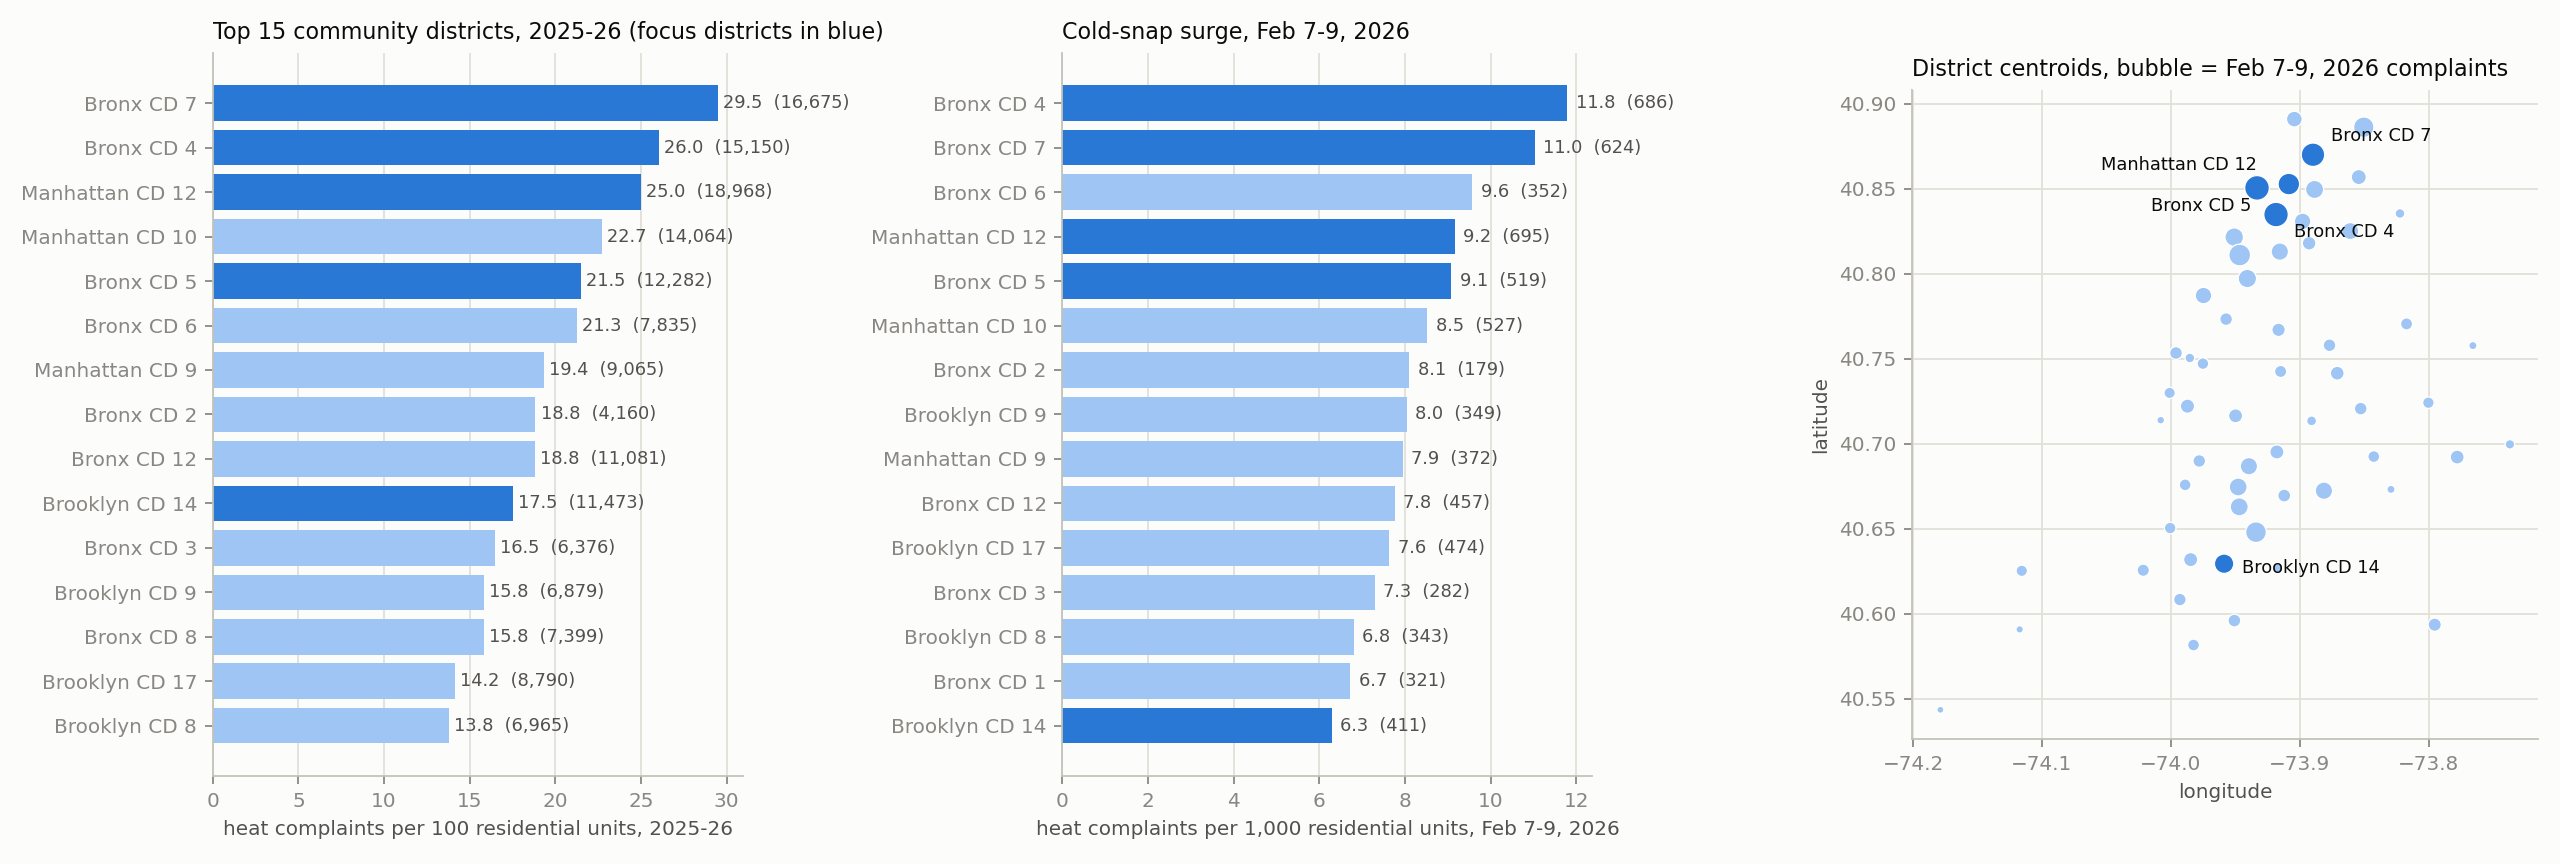

In [9]:
display(pd.read_csv(OUT / "focus_districts_table.csv").T)
cd = pd.read_csv(OUT / "cd_level_map_data.csv")
display(cd[~cd.is_joint_interest_area].nlargest(10, "complaints_per_100_units_2025_26")[["cd_label", "residential_units", "heat_complaints_2025_26", "complaints_per_100_units_2025_26", "feb7_9_2026_complaints", "chronic_buildings", "forecast_only_strict_buildings", "latitude_centroid", "longitude_centroid"]])
display(Image(filename=str(OUT / "fig_bronx_cd_impact.png")))

## Step 5: Deliverable 4, boiler defects and fuel joined on bin

In [10]:
%run s2_05_boiler_join.py

[14:54:08] load ...
[14:54:16] load done in 8.4 s
[14:54:16] DOB boiler features (pre-cutoff) ...
[14:54:43] DOB boiler features (pre-cutoff) done in 26.8 s
[14:54:43] DEP boiler fuel features (pre-cutoff) ...
[14:54:44] DEP boiler fuel features (pre-cutoff) done in 1.6 s
[14:54:44] join on bin ...
[14:54:45] join on bin done in 0.2 s
  universe 116,139 buildings; DOB boiler record on bin for 37.3% (3+ units: 54.7%); DEP fuel record for 25.1% (3+ units: 37.4%)
[14:54:45] lift ...
[14:54:45] lift done in 0.6 s
                level  buildings  share_failed48_2025_26  share_verified_2025_26  rate_7d_confirmation_2025_26  share_failed48_feb7_9
DOB record, no defect      24309                0.248879                0.045621                      0.099373               0.041302
  prior defect logged      14583                0.319482                0.069670                      0.118767               0.054241
                    group  buildings  share_dob_record  share_prior_defect_among_do

In [11]:
L = pd.read_csv(OUT / "boiler_lift_summary.csv")
display(L[(L.scope == "3+ unit buildings with a DOB boiler record")][["dimension", "level", "buildings", "share_failed48_2025_26", "share_verified_2025_26", "rate_7d_confirmation_2025_26", "share_failed48_feb7_9"]])
display(pd.read_csv(OUT / "boiler_profile_by_group.csv"))

,dimension,level,buildings,share_failed48_2025_26,share_verified_2025_26,rate_7d_confirmation_2025_26,share_failed48_feb7_9
33,"prior boiler defect (pre Oct 1, 2025)","DOB record, no defect",24309,0.248879,0.045621,0.099373,0.041302
34,"prior boiler defect (pre Oct 1, 2025)",prior defect logged,14583,0.319482,0.069670,0.118767,0.054241
35,count of prior defect reports,0 defects,24309,0.248879,0.045621,0.099373,0.041302
36,count of prior defect reports,1 defect,7307,0.298618,0.060901,0.111888,0.045162
37,count of prior defect reports,2-3 defects,5487,0.331875,0.074904,0.123584,0.060871
38,count of prior defect reports,4+ defects,1789,0.366685,0.089435,0.127225,0.070989
39,time since last DOB boiler inspection at cutoff,< 1 year,30485,0.276562,0.052813,0.101240,0.046187
40,time since last DOB boiler inspection at cutoff,1-2 years,5255,0.304853,0.062036,0.117810,0.051380
41,time since last DOB boiler inspection at cutoff,2-3 years,1530,0.249020,0.068627,0.165364,0.047059
42,time since last DOB boiler inspection at cutoff,3+ years,1622,0.181874,0.051788,0.168445,0.027744


,group,buildings,share_dob_record,share_prior_defect,share_prior_defect_among_dob,mean_defect_reports,share_late_filing,median_days_since_inspection,share_dep_record,mean_registration_age_years,share_oil_fuel,share_res3plus,buildings_3plus,share_dob_record_3plus,share_prior_defect_among_dob_3plus,mean_registration_age_years_3plus,share_oil_fuel_among_dep_3plus
0,chronic,38549,0.560066,0.229734,0.410190,0.481128,0.093284,204.0,0.409427,47.512450,0.190277,0.770266,29693,0.692587,0.411573,47.521567,0.464603
1,cold_only,17481,0.246839,0.081345,0.329548,0.174990,0.039986,222.0,0.143356,38.338787,0.068989,0.479950,8390,0.414899,0.320885,34.529470,0.463163
2,forecast_only_broad_extra,14991,0.458542,0.170836,0.372563,0.359349,0.077780,211.0,0.293176,38.129238,0.132546,0.722767,10835,0.590863,0.373633,37.856358,0.448136
3,forecast_only_strict,18814,0.277187,0.091474,0.330010,0.204954,0.045976,216.0,0.174019,40.329261,0.081694,0.517115,9729,0.437969,0.324102,36.610027,0.445848
4,no_training_complaints,26304,0.202859,0.060181,0.296664,0.130056,0.033987,233.0,0.121883,41.730505,0.060713,0.475289,12502,0.334586,0.293808,38.034550,0.482531


## Outputs

In [12]:
import os
for f in sorted(os.listdir(OUT)):
    print(f"{os.path.getsize(OUT / f)/1e6:8.2f} MB  {f}")

   18.32 MB  bin_boiler_features.csv
    0.02 MB  boiler_lift_summary.csv
    0.00 MB  boiler_profile_by_group.csv
    0.03 MB  cd_level_map_data.csv
    0.02 MB  council_district_summary.csv
    0.24 MB  fig_bronx_cd_impact.png
    0.29 MB  fig_forecast_only_regimes.png
    0.22 MB  fig_violation_confirmation.png
    0.00 MB  focus_districts_table.csv
   60.44 MB  forecast_only_buildings.csv
    0.00 MB  forecast_only_examples.csv
    0.00 MB  forecast_only_group_summary.csv
    0.00 MB  forecast_only_intensity_tiers.csv
    0.00 MB  forecast_only_precision_at_k.csv
    0.00 MB  forecast_only_reaction_by_forecast_trigger.csv
    0.03 MB  forecast_vs_observed_2025_26.csv
    0.00 MB  numbers_01_clean.json
    0.01 MB  numbers_02_violation_tier.json
    0.02 MB  numbers_03_geography.json
    0.04 MB  numbers_04_forecast_only.json
    0.01 MB  numbers_05_boiler_join.json
    0.02 MB  violation_confirmation_summary.csv
    0.38 MB  violation_saturation_by_day.csv
    0.00 MB  violation_sa